# Training and fine-tuning curves

In [1]:
import logging
import math
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

CHECKPOINTS = os.path.join("..", "checkpoints")
BASE_NAME = "const_split_bott_zigzag_1s14__seq256_knn7w_rank3"
LOG_PATH = os.path.join(CHECKPOINTS, BASE_NAME, "train.log")
FINETUNE_LOGS = {
    "ooa, 10 epochs, learning rate 2e-4": os.path.join(CHECKPOINTS, f"{BASE_NAME}_finetuned_ooa_10_epochs_lr_2e-4",
                                                       "finetune.log"),
    "Papuans, 10 epochs, learning rate 2e-4": os.path.join(
        CHECKPOINTS, f"{BASE_NAME}_finetuned_papuans_10j19_10_epochs_lr_2e-4", "finetune.log"),
}
# The fine-tunings of the figures: ooa with the setting of the Papuan run, and the Papuan run.
OOA_LABEL = "ooa, 10 epochs, learning rate 2e-4"
PAPUAN_LABEL = "Papuans, 10 epochs, learning rate 2e-4"
# The scenarios of the two fine-tunings in the panel titles, named as in the table of scenarios of the manuscript
# (tab:scenarios) and in a typewriter font: mathtext's \mathtt, which draws cmtt10 in the titles (style_panel).
OOA_SCENARIO = r"$\mathtt{ooa}$"
PAPUAN_SCENARIO = r"$\mathtt{pap}$"
BATCH_SIZE = 16
FIGURE_WIDTH, FIGURE_HEIGHT = 6.5, 4.6
# The figures of the supplement go to figures/, at the text width of the paper.
FIGURES_DIR = "figures"
FIGURE_DPI = 500
# DejaVu Sans ships with matplotlib. Without hinting, the Mac draws the same pixels as the saved figures. The PDF
# files get TrueType fonts (pdf.fonttype 42) in place of matplotlib's Type 3 fonts.
plt.rcParams.update({"font.family": "DejaVu Sans", "text.hinting": "no_hinting", "font.size": 8, "figure.dpi": 150,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 8,
                     "legend.frameon": False, "axes.formatter.useoffset": False, "pdf.fonttype": 42})
# Writing cmtt10, the font of the scenario names, into a PDF makes fontTools warn that the dates in the font file are
# early ("'created' timestamp seems very low"). The dates do not change the figure.
logging.getLogger("fontTools.ttLib.tables._h_e_a_d").setLevel(logging.ERROR)
SIZES = ["10", "20", "50"]
COLORS = {"training": "#000000", "validation": "#9A9A9A"}
SET_LABELS = {"training": "Training", "validation": "Validation"}
PARTS = {"one_minus_pearson": ("$1 - r$", "-"), "mse": ("MSE", "--"), "rank": ("Rank", ":")}
# The first epoch drawn for each set, in the training and in the fine-tuning.
TRAINING_FIRST_EPOCHS = {"training": 2, "validation": 1}
FINETUNING_FIRST_EPOCHS = {"training": 1, "validation": 0}
# Places of a value label around its dot, tried in order, in points: above, below, and the corners at 6 points, the
# sides, then above, below, and the corners at 10 and at 14 points.
LABEL_PLACES = [(0, 6, "center", "bottom"), (0, -6, "center", "top"), (-5, 6, "right", "bottom"),
                (-5, -6, "right", "top"), (5, 6, "left", "bottom"), (5, -6, "left", "top"),
                (-8, 0, "right", "center"), (8, 0, "left", "center")]
LABEL_PLACES += [(dx, sign * dy, ha, "bottom" if sign > 0 else "top") for dy in (10, 14)
                 for dx, ha in ((0, "center"), (-5, "right"), (5, "left")) for sign in (1, -1)]
# A row of the end-of-training table of src/train.py: size, set, and r, RF, and wrong triplets of input and network.
END_TABLE_ROW = re.compile(r"^\s+(\d+)\s+(in-dist|held-out) \|\s+(\S+)\s+(\S+)(?:\s+\S+){3} \|"
                           r"\s+(\S+)\s+(\S+)(?:\s+\S+){3} \|.*\|\s+(\S+)\s+(\S+)(?:\s+\S+){3}\s*$")
# An epoch line of src/finetune.py: epoch, training loss and correlation, held-out loss and correlation, and a mark.
FINETUNE_LINE = re.compile(
    r"^ *(\d+) \|\s+([-\d.]+)\s+([-\d.]+) \|\s+([-\d.]+)\s+([-\d.]+)\s*(\(input model\)|✓)?\s*$", re.M)
# The comparison at the end of src/finetune.py: a size with its positions, then a metric with base, fine-tuned, their
# difference, and the input tree, then one row per held-out file.
FINETUNE_COMPARISON_SIZE = re.compile(r"^  (?:S=(\d+)|ALL sizes pooled) \((\d+) trees\)\s*$")
FINETUNE_COMPARISON_ROW = re.compile(r"^ {4}(corr|RF|triplet acc) [↑↓]\s+(\S+)\s+(\S+)\s+(\S+)(?:\s+(\S+))?\s*$")
FINETUNE_FILE_ROW = re.compile(r"^ {4}(\S+\.trees)\s+(\d+) \|\s+(\S+)\s+(\S+) \|"
                               r"\s+(\S+)\s+(\S+) \|\s+(\S+)\s+(\S+)\s*$")
COMPARISON_METRICS = {"corr": "r", "RF": "RF distance", "triplet acc": "triplet accuracy"}

In [2]:
# The parser of the epoch, size, and time lines of a training or fine-tuning log, from plot_training_curves.py.
NUMBER = r"(-?[\d.]+)"
EPOCH_LINE = re.compile(rf"^ *(\d+) \|\s+{NUMBER}\s+{NUMBER} \|\s+{NUMBER}\s+{NUMBER}( ✓)?$", re.M)
PART_TEXT = rf"{NUMBER} \(1-pearson {NUMBER}, mse {NUMBER}, rank {NUMBER}\)"
SIZE_LINE = re.compile(rf"^ +S=(\d+) +TR {PART_TEXT} \| VA {PART_TEXT}$", re.M)
TIME_LINE = re.compile(rf"^ +time {NUMBER} s: training {NUMBER} s \(building batches {NUMBER} s\), "
                       rf"validation and saving {NUMBER} s \| lr ([\d.e+-]+)$", re.M)


def parse_log(text):
    """Read the epoch, per-size, and time lines of a train.log.

    Args:
        text (str): The content of train.log.

    Returns:
        tables (tuple): Three pandas.DataFrame, the training curves, the epoch times, and the training time.
    """
    rows, times = [], []
    saved_epoch = None
    lines = text.splitlines()
    epoch = None
    for line in lines:
        match = EPOCH_LINE.match(line)
        if match:
            epoch = int(match.group(1))
            rows.append({"epoch": epoch, "size": "all", "set": "training", "loss": float(match.group(2))})
            rows.append({"epoch": epoch, "size": "all", "set": "validation", "loss": float(match.group(4))})
            if match.group(6):
                saved_epoch = epoch
            continue
        match = SIZE_LINE.match(line)
        if match and epoch is not None:
            values = [float(v) for v in match.groups()[1:]]
            for offset, name in ((0, "training"), (4, "validation")):
                rows.append({"epoch": epoch, "size": match.group(1), "set": name, "loss": values[offset],
                             "one_minus_pearson": values[offset + 1], "mse": values[offset + 2],
                             "rank": values[offset + 3]})
            continue
        match = TIME_LINE.match(line)
        if match and epoch is not None:
            values = [float(v) for v in match.groups()]
            times.append({"epoch": epoch, "epoch_s": values[0], "training_s": values[1], "batches_s": values[2],
                          "validation_and_saving_s": values[3], "learning_rate": values[4]})
    summary = {"saved_epoch": saved_epoch}
    for key, pattern in (("loading_s", r"Loading time: ([\d.]+) s"),
                         ("total_training_s", r"Total training time: ([\d.]+) s"),
                         ("end_table_s", r"End table time: ([\d.]+) s")):
        match = re.search(pattern, text)
        summary[key] = float(match.group(1)) if match else None
    return pd.DataFrame(rows), pd.DataFrame(times), pd.DataFrame([summary])


def read_window_counts(log_text):
    """Training and validation windows of each size, from the header of a training or fine-tuning log."""
    rows = [{"size": size, "training": int(training), "validation": int(validation)}
            for size, training, validation in re.findall(r"^\s+S=(\d+): (\d+) train / (\d+) val seqs", log_text, re.M)]
    return pd.DataFrame(rows).set_index("size")


def combine_sizes(curves_df, windows_df, column):
    """One column of the curves, combined over the sizes of windows_df in proportion to their batches."""
    sizes = list(windows_df.index)
    frames = []
    for name in ("training", "validation"):
        # Each size counts by its batches of BATCH_SIZE windows, as in the mean over batches of src/train.py.
        batches = {size: math.ceil(windows_df.loc[size, name] / BATCH_SIZE) for size in sizes}
        part_df = curves_df[(curves_df["set"] == name) & curves_df["size"].isin(sizes)]
        wide_df = part_df.pivot(index="epoch", columns="size", values=column)
        combined = sum(wide_df[size] * batches[size] for size in sizes) / sum(batches.values())
        frames.append(pd.DataFrame({"epoch": combined.index, "set": name, column: combined.to_numpy()}))
    return pd.concat(frames, ignore_index=True)


def fill_combined(curves_df, windows_df, columns):
    """Put the combined value of each column in the rows of all sizes combined."""
    curves_df = curves_df.copy()
    for column in columns:
        combined_df = combine_sizes(curves_df, windows_df, column)
        for name in ("training", "validation"):
            values = combined_df[combined_df["set"] == name].set_index("epoch")[column]
            rows = (curves_df["size"] == "all") & (curves_df["set"] == name)
            curves_df.loc[rows, column] = curves_df.loc[rows, "epoch"].map(values)
    return curves_df


def largest_combination_difference(curves_df, windows_df):
    """Largest difference between the combined loss of a log and the mean of its sizes weighted by their batches."""
    check_df = combine_sizes(curves_df, windows_df, "loss").merge(
        curves_df[curves_df["size"] == "all"][["epoch", "set", "loss"]], on=["epoch", "set"],
        suffixes=("_sizes", "_log"))
    return (check_df["loss_sizes"] - check_df["loss_log"]).abs().max()


def read_end_table(log_text):
    """The rows of the end-of-training table: the input tree and the network, per scenario and size."""
    rows, scenario = [], None
    for line in log_text.splitlines():
        header = re.match(r"^=== (?:scenario: (\S+)|ALL scenarios pooled) ===", line)
        if header:
            scenario = header[1] or "all"
            continue
        match = END_TABLE_ROW.match(line)
        if match and scenario:
            rows.append({"scenario": scenario, "size": match[1], "corr_in": float(match[3]),
                         "corr_mod": float(match[4]), "rf_in": float(match[5]), "rf_mod": float(match[6]),
                         "wrong_triplets_in": float(match[7]), "wrong_triplets_mod": float(match[8])})
    return pd.DataFrame(rows)


def read_finetune_curves(log_text):
    """Loss and its parts per size and set of each epoch of a fine-tuning log, epoch 0 included."""
    curves_df = parse_log(log_text)[0]
    # parse_log starts at epoch 1, since the line of epoch 0 ends with "(input model)".
    lines = log_text.splitlines()
    start = next(k for k, line in enumerate(lines) if line.endswith("(input model)"))
    match = FINETUNE_LINE.match(lines[start])
    rows = [{"epoch": 0, "size": "all", "set": "training", "loss": float(match[2])},
            {"epoch": 0, "size": "all", "set": "validation", "loss": float(match[4])}]
    for line in lines[start + 1:]:
        size_match = SIZE_LINE.match(line)
        if not size_match:
            break
        values = [float(value) for value in size_match.groups()[1:]]
        for offset, name in ((0, "training"), (4, "validation")):
            rows.append({"epoch": 0, "size": size_match[1], "set": name, "loss": values[offset],
                         "one_minus_pearson": values[offset + 1], "mse": values[offset + 2],
                         "rank": values[offset + 3]})
    return pd.concat([pd.DataFrame(rows), curves_df], ignore_index=True)


def read_finetune_comparison(log_text):
    """Base and fine-tuned r, RF distance, and triplet accuracy per size, from the end of a fine-tuning log."""
    rows, size, positions = [], None, None
    # The comparison follows its header line, at the end of the log.
    for line in log_text.partition("Held-out test: fine-tuned vs base")[2].splitlines():
        size_match = FINETUNE_COMPARISON_SIZE.match(line)
        if size_match:
            size, positions = size_match[1] or "all", int(size_match[2])
            continue
        match = FINETUNE_COMPARISON_ROW.match(line)
        if match and size:
            rows.append({"size": size, "metric": COMPARISON_METRICS[match[1]], "positions": positions,
                         "base": float(match[2]), "fine-tuned": float(match[3]), "difference": float(match[4]),
                         "input tree": float(match[5]) if match[5] else math.nan})
    columns = ["size", "metric", "positions", "base", "fine-tuned", "difference", "input tree"]
    return pd.DataFrame(rows, columns=columns).set_index(["size", "metric"])


def read_finetune_files(log_text):
    """Base and fine-tuned r, RF distance, and triplet accuracy of each held-out file of a fine-tuning log."""
    rows, size = [], None
    for line in log_text.partition("Held-out test: fine-tuned vs base")[2].splitlines():
        size_match = FINETUNE_COMPARISON_SIZE.match(line)
        if size_match:
            size = size_match[1] or "all"
            continue
        match = FINETUNE_FILE_ROW.match(line)
        if match and size:
            values = [float(value) for value in match.groups()[2:]]
            rows.append({"size": size, "file": match[1], "positions": int(match[2]),
                         "r base": values[0], "r fine-tuned": values[1], "RF base": values[2],
                         "RF fine-tuned": values[3], "triplet accuracy base": values[4],
                         "triplet accuracy fine-tuned": values[5]})
    files_df = pd.DataFrame(rows)
    for metric in ("r", "RF", "triplet accuracy"):
        files_df[f"{metric} difference"] = files_df[f"{metric} fine-tuned"] - files_df[f"{metric} base"]
    return files_df


def series(curves_df, size, name, column, first_epochs):
    """Epochs and values of one size, set, and column, from the first epoch drawn for that set."""
    rows_df = curves_df[(curves_df["size"] == size) & (curves_df["set"] == name)
                        & (curves_df["epoch"] >= first_epochs[name])].sort_values("epoch")
    return rows_df["epoch"].to_numpy(), rows_df[column].to_numpy()


def style_panel(axis, ticks, title, letter):
    """Epoch ticks, room for the value labels, and the bold panel letter and the title above the panel."""
    axis.set_xticks(ticks)
    # Room right of the last epoch, and above and below the curves, for the value labels.
    axis.set_xlim(ticks[0] - 0.5, ticks[-1] + (ticks[-1] - ticks[0]) * 0.055)
    axis.margins(y=0.25)
    axis.annotate(letter, (0, 1), xycoords="axes fraction", xytext=(0, 6), textcoords="offset points",
                  fontweight="bold", fontsize=9, ha="left", va="bottom")
    # The mathtext of a title, the scenario of the fine-tuning, takes the Computer Modern fonts, so \mathtt is cmtt10.
    axis.annotate(title, (0, 1), xycoords="axes fraction", xytext=(11, 6), textcoords="offset points",
                  ha="left", va="bottom", math_fontfamily="cm")


def draw_loss(axis, curves_df, size, first_epochs):
    """Training and validation loss of one size; returns the epochs and values of the validation curve."""
    for name in ("training", "validation"):
        epochs, values = series(curves_df, size, name, "loss", first_epochs)
        axis.plot(epochs, values, color=COLORS[name], linewidth=1.3)
    return series(curves_df, size, "validation", "loss", first_epochs)


def draw_parts(axis, curves_df, size, first_epochs):
    """Change of each part of the loss from the first epoch drawn, for the training and the validation curve."""
    for name in ("training", "validation"):
        for part, (label, style) in PARTS.items():
            epochs, values = series(curves_df, size, name, part, first_epochs)
            axis.plot(epochs, values - values[0], style, color=COLORS[name], linewidth=1.4 if style == ":" else 1.2)
    axis.axhline(0, color="0.8", linewidth=0.6, zorder=0)


def mark_values(axis, epochs, values, first_too):
    """Dots on the last validation value, and on the first one too; returns the values to label."""
    indices = [len(values) - 1] + ([0] if first_too else [])
    for index in indices:
        axis.plot(epochs[index], values[index], "o", color=COLORS["validation"], markersize=3.5, zorder=3)
    return [(axis, epochs[index], values[index]) for index in indices]


def line_paths(axis):
    """The curves of a panel in display coordinates, without the dots."""
    return [line.get_transform().transform_path(line.get_path()) for line in axis.get_lines()
            if len(line.get_xdata()) > 1]


def place_label(figure, axis, x, y, text, placed):
    """Put a value label at the first place of LABEL_PLACES inside the panel that touches no line and no label."""
    renderer = figure.canvas.get_renderer()
    figure.draw_without_rendering()
    # One point in pixels, so the label keeps 1 point from the lines and the axes at any resolution.
    point = figure.dpi / 72
    paths, panel = line_paths(axis), axis.get_window_extent(renderer).padded(-point)
    for dx, dy, ha, va in LABEL_PLACES:
        label = axis.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va)
        label.set_in_layout(False)
        figure.draw_without_rendering()
        box = label.get_window_extent(renderer).padded(point)
        inside = panel.x0 <= box.x0 and box.x1 <= panel.x1 and panel.y0 <= box.y0 and box.y1 <= panel.y1
        clear = not any(path.intersects_bbox(box, filled=False) for path in paths)
        if inside and clear and not any(box.overlaps(other) for other in placed):
            placed.append(box)
            return
        label.remove()
    raise RuntimeError(f"no place for the label {text} that touches no line")


def add_legend(figure, parts):
    """One legend across the top of the figure: the two sets, and in the figures of the parts their line styles."""
    if parts:
        handles = [Line2D([], [], color=COLORS[name], marker="s", linestyle="none", markersize=5,
                          label=SET_LABELS[name]) for name in COLORS]
        handles += [Line2D([], [], color="black", linestyle=style, linewidth=1.4 if style == ":" else 1.2,
                           label=label) for label, style in PARTS.values()]
    else:
        handles = [Line2D([], [], color=COLORS[name], linewidth=1.3, label=SET_LABELS[name]) for name in COLORS]
    figure.legend(handles=handles, loc="outside upper center", ncol=len(handles))


def finish(figure, panels, parts, requests, output_pdf=None):
    """Axis labels, legend, value labels, and the figure, written to output_pdf if given."""
    ylabel = "Change from first epoch" if parts else "Loss"
    panels[0].set_ylabel(ylabel)
    panels[-3].set_ylabel(ylabel)
    for axis in panels[-3:]:
        axis.set_xlabel("Epoch")
    add_legend(figure, parts)
    figure.draw_without_rendering()
    # The layout stays as it is now, so the panels keep their size under the value labels.
    figure.set_layout_engine("none")
    placed = []
    for axis, x, y in requests:
        place_label(figure, axis, x, y, f"{y:.4f}", placed)
    # The figure is written before plt.show, which closes it.
    if output_pdf:
        figure.savefig(output_pdf, dpi=FIGURE_DPI)
        print("written:", output_pdf)
    plt.show()


def plot_training(curves_df, parts, output_pdf=None):
    """All sizes combined across the top and one panel per size below, for the loss or for the change of its parts."""
    figure = plt.figure(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
    grid = figure.add_gridspec(2, 3)
    panels = [(figure.add_subplot(grid[0, :]), "all", "Combined")]
    panels += [(figure.add_subplot(grid[1, column]), size, f"{size} haplotypes") for column, size in enumerate(SIZES)]
    requests = []
    for (axis, size, title), letter in zip(panels, "abcd"):
        if parts:
            draw_parts(axis, curves_df, size, TRAINING_FIRST_EPOCHS)
        else:
            epochs, values = draw_loss(axis, curves_df, size, TRAINING_FIRST_EPOCHS)
            requests += mark_values(axis, epochs, values, first_too=False)
        style_panel(axis, [0, 5, 10, 15, 20, 25, 30], title, letter)
    finish(figure, [axis for axis, _, _ in panels], parts, requests, output_pdf)


def plot_finetuning(finetune_curves, parts, output_pdf=None):
    """ooa and the Papuan model across the top and ooa per size below, for the loss or the change of its parts."""
    missing = [label for label in (OOA_LABEL, PAPUAN_LABEL) if label not in finetune_curves]
    if missing:
        print("no log for:", *missing)
        return
    figure = plt.figure(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
    grid = figure.add_gridspec(2, 3)
    ooa_df, papuan_df = finetune_curves[OOA_LABEL], finetune_curves[PAPUAN_LABEL]
    panels = [(figure.add_subplot(grid[0, :2]), ooa_df, "all", f"Combined ({OOA_SCENARIO})"),
              (figure.add_subplot(grid[0, 2]), papuan_df, "all", f"52 haplotypes ({PAPUAN_SCENARIO})")]
    panels += [(figure.add_subplot(grid[1, column]), ooa_df, size, f"{size} haplotypes ({OOA_SCENARIO})")
               for column, size in enumerate(SIZES)]
    requests = []
    for (axis, curves_df, size, title), letter in zip(panels, "abcde"):
        if parts:
            draw_parts(axis, curves_df, size, FINETUNING_FIRST_EPOCHS)
        else:
            epochs, values = draw_loss(axis, curves_df, size, FINETUNING_FIRST_EPOCHS)
            requests += mark_values(axis, epochs, values, first_too=True)
        style_panel(axis, [0, 2, 4, 6, 8, 10], title, letter)
    finish(figure, [axis for axis, _, _, _ in panels], parts, requests, output_pdf)


def table_at_epoch(curves_df, epoch):
    """Loss, correlation, MSE, and rank of every size and set at one epoch."""
    epoch_df = curves_df[curves_df["epoch"] == epoch].set_index(["size", "set"])
    order = [(size, name) for size in ["all", *SIZES] for name in ("training", "validation")]
    return epoch_df.loc[order, ["loss", "r", "mse", "rank"]].round(4)


def time_table(times_df, summary_df):
    """Loading time, time of the epochs, and total training time once the log has it."""
    summary = summary_df.iloc[0].apply(pd.to_numeric, errors="coerce")
    rows = {"loading (h)": summary["loading_s"] / 3600,
            "mean time of an epoch (min)": times_df["epoch_s"].mean() / 60,
            "sum of the epochs in the log (h)": times_df["epoch_s"].sum() / 3600,
            "total training time from the log (h)": summary["total_training_s"] / 3600,
            "end table (min)": summary["end_table_s"] / 60}
    values = {"epochs in the log": str(len(times_df))}
    values.update({label: "not in the log yet" if pd.isna(value) else f"{value:.2f}" for label, value in rows.items()})
    return pd.Series(values).to_frame("value")

In [3]:
# Curves, epoch times, and summary of the training log, read by parse_log.
with open(LOG_PATH) as log_file:
    LOG_TEXT = log_file.read()
curves_df, times_df, summary_df = parse_log(LOG_TEXT)
windows_df = read_window_counts(LOG_TEXT)
end_table_df = read_end_table(LOG_TEXT)
REPORTED_EPOCH = int(summary_df["saved_epoch"].iloc[0])
# The correlation r of each size, from the 1 - r part of its loss.
curves_df["r"] = 1 - curves_df["one_minus_pearson"]
# Known answer: the combined loss of the log equals the mean of the sizes weighted by their batches, up to rounding.
print(f"training: epochs in the log {curves_df['epoch'].max()} | reported epoch {REPORTED_EPOCH} | largest "
      f"difference between the combined loss of the log and the weighted mean of the sizes "
      f"{largest_combination_difference(curves_df, windows_df):.5f}")
# The parts and r of all sizes combined, with the same weights.
curves_df = fill_combined(curves_df, windows_df, ["one_minus_pearson", "mse", "rank", "r"])
# The text and the curves of each fine-tuning log, with the same known answer and combination.
FINETUNE_TEXTS, finetune_curves = {}, {}
for label, path in FINETUNE_LOGS.items():
    if not os.path.exists(path):
        print(f"{label}: no log at {path}")
        continue
    with open(path) as log_file:
        FINETUNE_TEXTS[label] = log_file.read()
    finetune_df = read_finetune_curves(FINETUNE_TEXTS[label])
    finetune_windows_df = read_window_counts(FINETUNE_TEXTS[label])
    print(f"{label}: epochs {finetune_df['epoch'].max()} | largest difference between the combined loss of the log "
          f"and the weighted mean of the sizes {largest_combination_difference(finetune_df, finetune_windows_df):.5f}")
    finetune_curves[label] = fill_combined(finetune_df, finetune_windows_df, ["one_minus_pearson", "mse", "rank"])
windows_df

training: epochs in the log 30 | reported epoch 30 | largest difference between the combined loss of the log and the weighted mean of the sizes 0.00008
ooa, 10 epochs, learning rate 2e-4: epochs 10 | largest difference between the combined loss of the log and the weighted mean of the sizes 0.00005


Papuans, 10 epochs, learning rate 2e-4: epochs 10 | largest difference between the combined loss of the log and the weighted mean of the sizes 0.00000


,training,validation
size,,
10,10270,2049
20,13115,2620
50,17035,3407


## Loss

The training and validation loss of all sizes combined (a) and of each size (b to d), with the last validation value, the loss of the reported epoch.

written: figures/training_loss.pdf


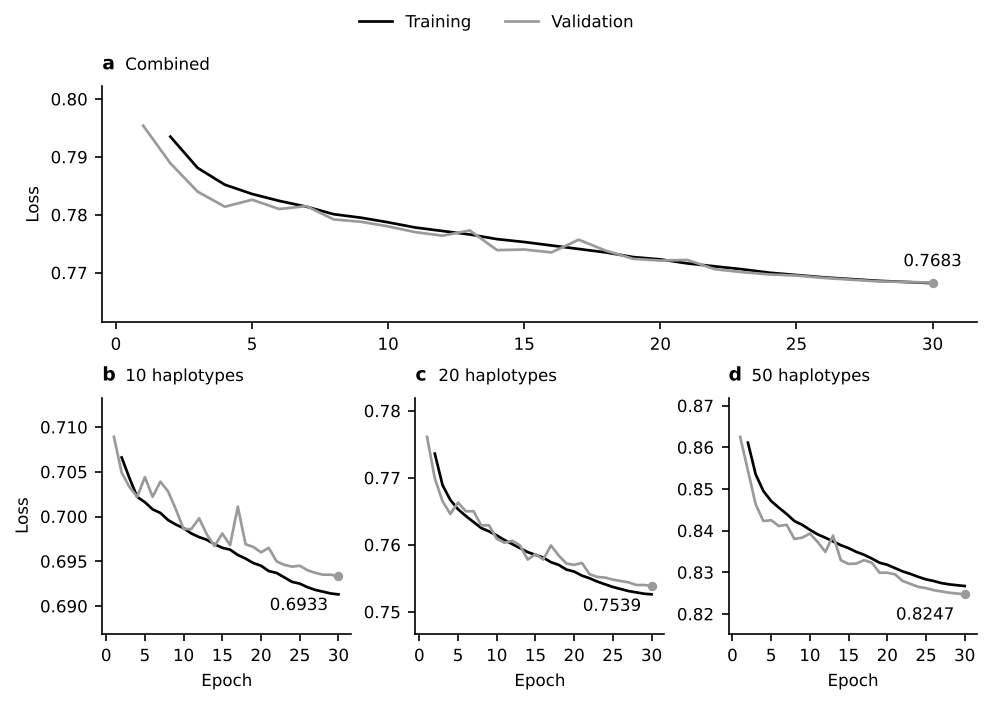

In [4]:
# Training and validation loss of all sizes combined on top, and of each size below, for the supplement.
plot_training(curves_df, parts=False, output_pdf=os.path.join(FIGURES_DIR, "training_loss.pdf"))

## Parts of the loss

The change of each part of the loss from the first epoch drawn, for the training and the validation curve, in the layout of the loss.

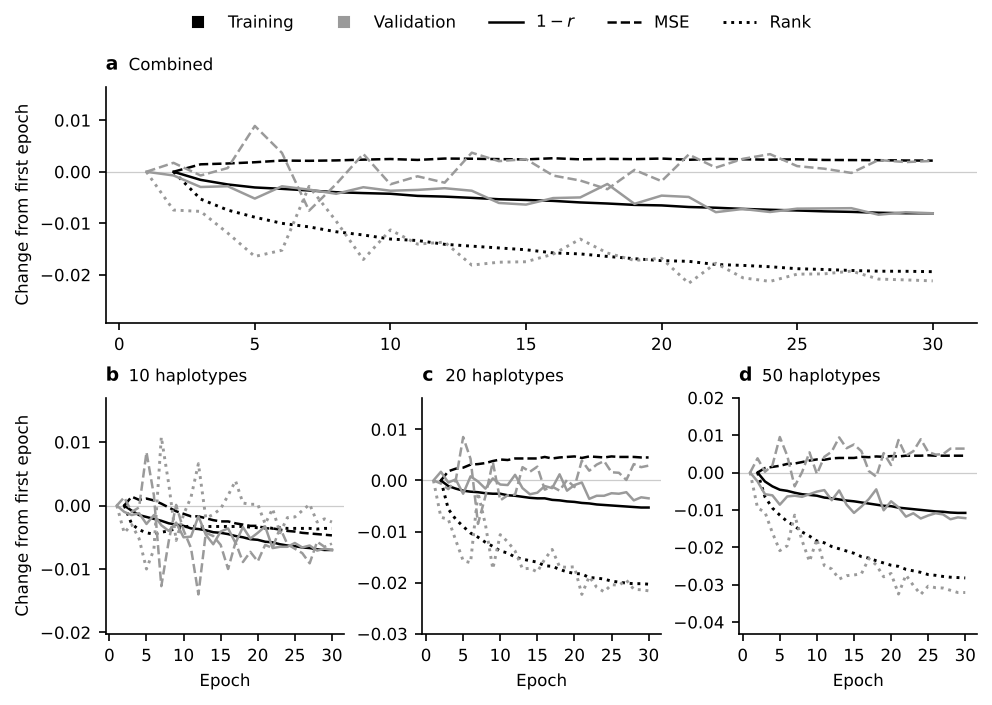

In [5]:
# Change of each part of the loss from the first epoch drawn, in the layout of the loss.
plot_training(curves_df, parts=True)

## Results per epoch

- `table_at_epoch`: the loss, $r$, MSE, and rank of every size and set at the reported epoch.
- `time_table`: the loading time, the time of the epochs, and the total training time.

In [6]:
# Loss, r, MSE, and rank of every size and set at the reported epoch.
table_at_epoch(curves_df, REPORTED_EPOCH)

loss       r     mse    rank
size set                                       
all  training    0.7682  0.8517  0.0699  0.5501
     validation  0.7683  0.8502  0.0737  0.5448
10   training    0.6913  0.8581  0.0726  0.4768
     validation  0.6933  0.8568  0.0765  0.4736
20   training    0.7526  0.8561  0.0742  0.5345
     validation  0.7539  0.8541  0.0785  0.5295
50   training    0.8267  0.8445  0.0650  0.6062
     validation  0.8247  0.8431  0.0682  0.5996

In [7]:
# Loading time, time of the epochs, and total training time.
time_table(times_df, summary_df)

,value
epochs in the log,30
loading (h),1.79
mean time of an epoch (min),83.49
sum of the epochs in the log (h),41.75
total training time from the log (h),41.75
end table (min),37.94


## End-of-training table

- `end_table_df`: the $r$, RF distance, and fraction of wrong triplets of the input tree (`_in`) and of the network (`_mod`), per scenario and size, with the scenarios pooled in the rows `all`.

In [8]:
# Input tree and network per scenario and size, from the end-of-training table.
end_table_df.set_index(["scenario", "size"]).round(4)

corr_in  corr_mod  rf_in  rf_mod  wrong_triplets_in  \
scenario    size                                                        
const       10     0.3805    0.8780   8.73    3.61             0.4493   
            20     0.4142    0.8748  20.71   10.92             0.4339   
            50     0.4343    0.8623  59.54   42.38             0.4237   
split       10     0.4772    0.8483   8.39    4.17             0.3919   
            20     0.5239    0.8534  21.59   12.35             0.3665   
            50     0.5465    0.8414  58.54   42.15             0.3551   
bott        10     0.5420    0.9011   8.61    4.85             0.3568   
            20     0.5499    0.9072  23.03   15.37             0.3539   
            50     0.5467    0.8924  67.96   53.84             0.3618   
zigzag_1s14 10     0.3475    0.8295   9.07    4.02             0.4682   
            20     0.3864    0.8325  23.65   13.27             0.4544   
            50     0.4442    0.8307  58.86   41.45             0.4217   
all         10     0.4368    0.8642   8.70    4.16             0.4165   
            20     0.4686    0.8670  22.24   12.98             0.4021   
            50     0.4929    0.8567  61.23   44.95             0.3906   

                  wrong_triplets_mod  
scenario    size                      
const       10                0.1348  
            20                0.1411  
            50                0.1491  
split       10                0.1650  
            20                0.1647  
            50                0.1647  
bott        10                0.1216  
            20                0.1198  
            50                0.1235  
zigzag_1s14 10                0.1920  
            20                0.1912  
            50                0.1888  
all         10                0.1533  
            20                0.1542  
            50                0.1565

## Fine-tuning

- `plot_finetuning(finetune_curves, parts=False)`: the training and validation loss of ooa with 10 epochs and learning rate 2e-4, all sizes combined (a) and per size (c to e), and of the Papuan model at 52 haplotypes (b), with the base model at epoch 0 and the last validation value.
- `plot_finetuning(finetune_curves, parts=True)`: the change of each part of the loss from the first epoch drawn, in the same layout.
- `read_finetune_comparison`: the table at the end of each log, with the base model and the saved fine-tuned model on the held-out files, per size and with the sizes pooled, and the input tree of the network. The held-out files also choose the saved epoch, so they are validation files, not test files.
- `read_finetune_files`: the base and fine-tuned values for each held-out file.

written: figures/finetuning_loss.pdf


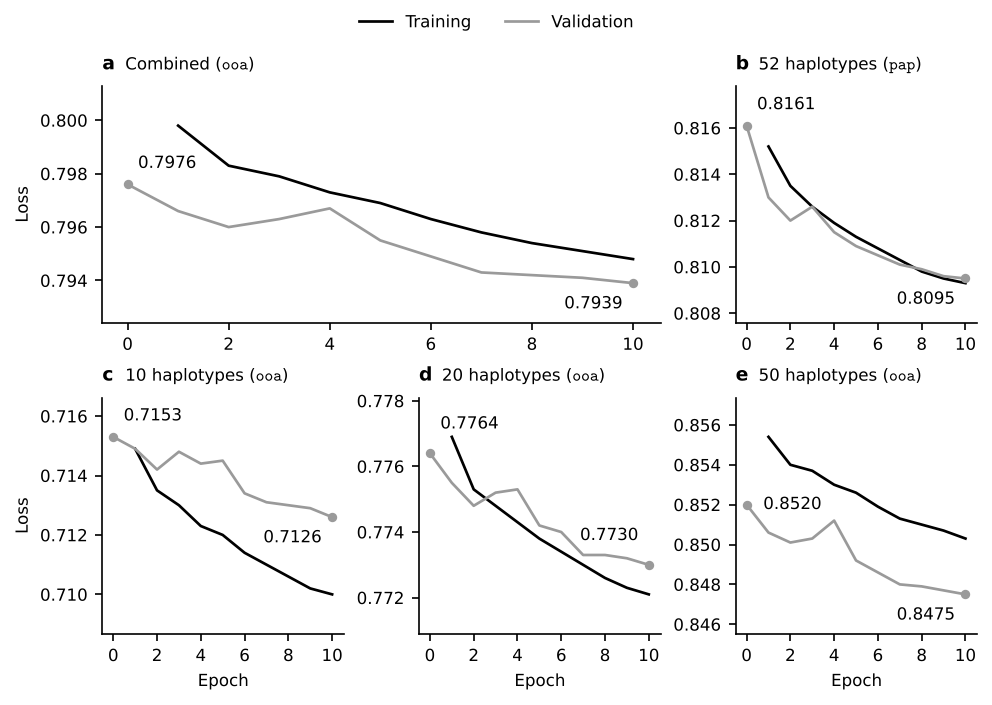

In [9]:
# Training and validation loss of ooa and of the Papuan model, from epoch 0, the base model, for the supplement.
plot_finetuning(finetune_curves, parts=False,
                output_pdf=os.path.join(FIGURES_DIR, "finetuning_loss.pdf"))

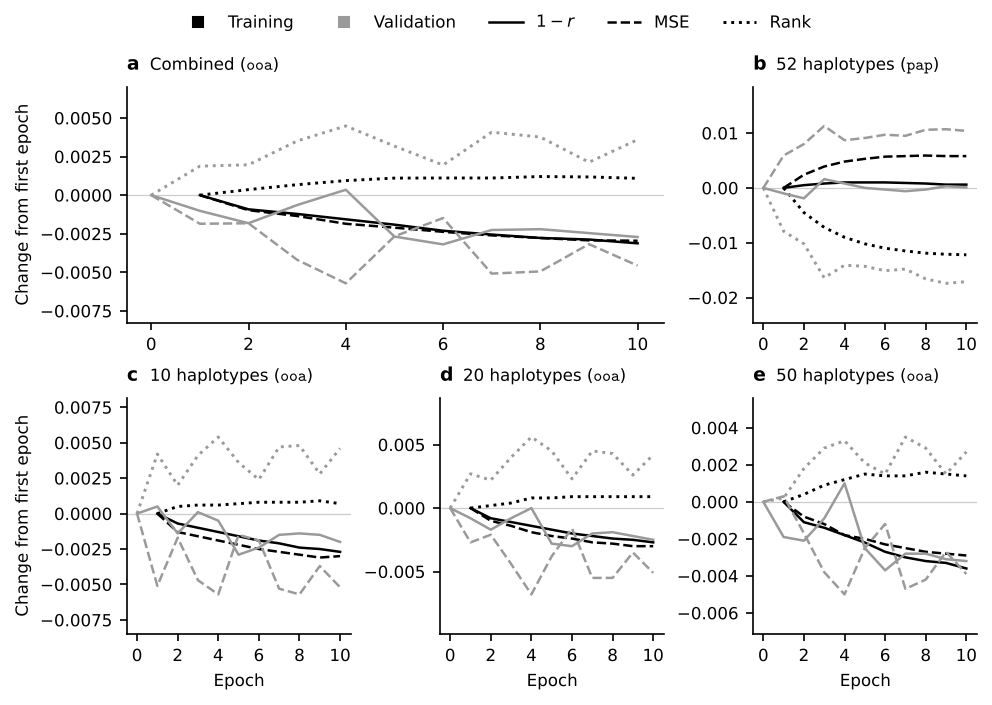

In [10]:
# Change of each part of the loss from the first epoch drawn, in the layout of the fine-tuning loss.
plot_finetuning(finetune_curves, parts=True)

In [11]:
# Base and saved fine-tuned model on the held-out files, from the end of each log.
for label, log_text in FINETUNE_TEXTS.items():
    print(label)
    display(read_finetune_comparison(log_text).round(4))

ooa, 10 epochs, learning rate 2e-4


positions     base  fine-tuned  difference  input tree
size metric                                                                  
10   r                      4852   0.8387      0.8404      0.0017      0.3888
     RF distance            4852   5.0260      4.9918     -0.0342     10.0185
     triplet accuracy       4852   0.8133      0.8178      0.0045      0.5597
20   r                      4889   0.8421      0.8444      0.0023      0.4386
     RF distance            4889  16.3174     16.1346     -0.1829     26.2532
     triplet accuracy       4889   0.8111      0.8170      0.0059      0.5843
50   r                      4943   0.8340      0.8370      0.0030      0.4942
     RF distance            4943  55.6399     55.3340     -0.3059     72.5794
     triplet accuracy       4943   0.8046      0.8096      0.0050      0.6140
all  r                     14684   0.8382      0.8406      0.0024      0.4409
     RF distance           14684  25.8233     25.6482     -0.1752     36.4834
     triplet accuracy      14684   0.8096      0.8148      0.0051      0.5862

Papuans, 10 epochs, learning rate 2e-4


positions     base  fine-tuned  difference  input tree
size metric                                                                  
52   r                      4984   0.8477      0.8478      0.0002      0.4674
     RF distance            4984  48.7223     48.2500     -0.4723     64.1581
     triplet accuracy       4984   0.8357      0.8376      0.0020      0.5974

In [12]:
# The same for each held-out file.
for label, log_text in FINETUNE_TEXTS.items():
    print(label)
    display(read_finetune_files(log_text).round(4))

ooa, 10 epochs, learning rate 2e-4


,size,file,positions,r base,r fine-tuned,RF base,RF fine-tuned,triplet accuracy base,triplet accuracy fine-tuned,r difference,RF difference,triplet accuracy difference
0,10,ooa_S10_22.trees,969,0.8458,0.8473,4.7141,4.6811,0.8220,0.8261,0.0015,-0.0330,0.0041
1,10,ooa_S10_13.trees,995,0.8402,0.8421,5.1477,5.0673,0.8167,0.8212,0.0019,-0.0804,0.0045
2,10,ooa_S10_4.trees,960,0.8417,0.8432,5.1854,5.1771,0.8111,0.8180,0.0015,-0.0083,0.0069
3,10,ooa_S10_9.trees,964,0.8268,0.8283,5.1971,5.1992,0.8008,0.8047,0.0015,0.0021,0.0039
4,10,ooa_S10_20.trees,964,0.8389,0.8411,4.8838,4.8340,0.8157,0.8191,0.0022,-0.0498,0.0034
5,20,ooa_S20_17.trees,985,0.8495,0.8526,16.2030,15.9939,0.8178,0.8245,0.0031,-0.2091,0.0067
6,20,ooa_S20_9.trees,980,0.8410,0.8431,16.0388,15.8898,0.8081,0.8136,0.0021,-0.1490,0.0055
7,20,ooa_S20_15.trees,971,0.8385,0.8407,16.7580,16.5911,0.8065,0.8111,0.0022,-0.1669,0.0046
8,20,ooa_S20_11.trees,973,0.8368,0.8385,16.1089,15.9548,0.8107,0.8167,0.0017,-0.1541,0.0060
9,20,ooa_S20_7.trees,980,0.8446,0.8468,16.4816,16.2469,0.8123,0.8189,0.0022,-0.2347,0.0066


Papuans, 10 epochs, learning rate 2e-4


,size,file,positions,r base,r fine-tuned,RF base,RF fine-tuned,triplet accuracy base,triplet accuracy fine-tuned,r difference,RF difference,triplet accuracy difference
0,52,papuans_10j19_S52_22.trees,998,0.8425,0.8426,48.6212,48.2826,0.8320,0.8332,0.0001,-0.3386,0.0012
1,52,papuans_10j19_S52_13.trees,997,0.8484,0.8479,48.1083,47.6008,0.8386,0.8395,-0.0005,-0.5075,0.0009
2,52,papuans_10j19_S52_4.trees,997,0.8514,0.8524,49.3501,48.7382,0.8381,0.8392,0.0010,-0.6119,0.0011
3,52,papuans_10j19_S52_9.trees,996,0.8522,0.8524,48.9618,48.4759,0.8406,0.8441,0.0002,-0.4859,0.0035
4,52,papuans_10j19_S52_20.trees,996,0.8438,0.8437,48.5703,48.1526,0.8291,0.8322,-0.0001,-0.4177,0.0031
